# AnomaForge — Master Colab Notebook

## Stage 1: Explore the MVTec AD `bottle` dataset

**Goal:** Confirm our dataset paths, inspect normal and defective sample images, view a real matching ground-truth defect mask, and check the planned **224 × 224** model-input shape.


## 1. Mount Google Drive

Upload/extract the official MVTec AD `bottle` folder from Drive before running the remaining cells.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Pointing the notebook to the extracted bottle folder

The  folder should directly contain the `train/`, `test/`, and `ground_truth/` directories. Edit the path if necessary according to your drive path guys

In [2]:
from pathlib import Path

# EDIT THIS if you extracted the bottle folder somewhere else.
BOTTLE_DIR = Path('/content/drive/MyDrive/ANOMAFORGE/bottle')

required = ['train/good', 'test/good', 'ground_truth']
missing = [x for x in required if not (BOTTLE_DIR / x).is_dir()]
if missing:
    raise FileNotFoundError(
        f"Could not find the expected folders under {BOTTLE_DIR}.\n"
        f"Missing: {missing}\n"
        "Extract the official 'bottle' category into Drive and update BOTTLE_DIR."
    )
print('Dataset folder found:', BOTTLE_DIR)

Dataset folder found: /content/drive/MyDrive/ANOMAFORGE/bottle


## 3. Count images and inspect the available labels

The training split should consist of normal images. The test split contains normal images and actual defects. We do not use real defect masks to train our models.

In [3]:
def image_files(folder):
    return sorted(p for p in folder.glob('*.png') if p.is_file())

print('Training categories:')
for folder in sorted((BOTTLE_DIR / 'train').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} images')

print('\nTest categories:')
for folder in sorted((BOTTLE_DIR / 'test').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} images')

print('\nGround-truth mask categories:')
for folder in sorted((BOTTLE_DIR / 'ground_truth').iterdir()):
    if folder.is_dir():
        print(f'  {folder.name:18s} : {len(image_files(folder))} masks')

Training categories:
  good               : 209 images

Test categories:
  broken_large       : 20 images
  broken_small       : 22 images
  contamination      : 21 images
  good               : 20 images

Ground-truth mask categories:
  broken_large       : 20 masks
  broken_small       : 22 masks
  contamination      : 21 masks


## 4. Visualizing one normal image and one real defective image

The official MVTec AD naming convention pairs a defective image such as `002.png` with a mask named `002_mask.png` inside the matching `ground_truth/<defect_type>/` folder. Wrote this as a dataset-inspection step

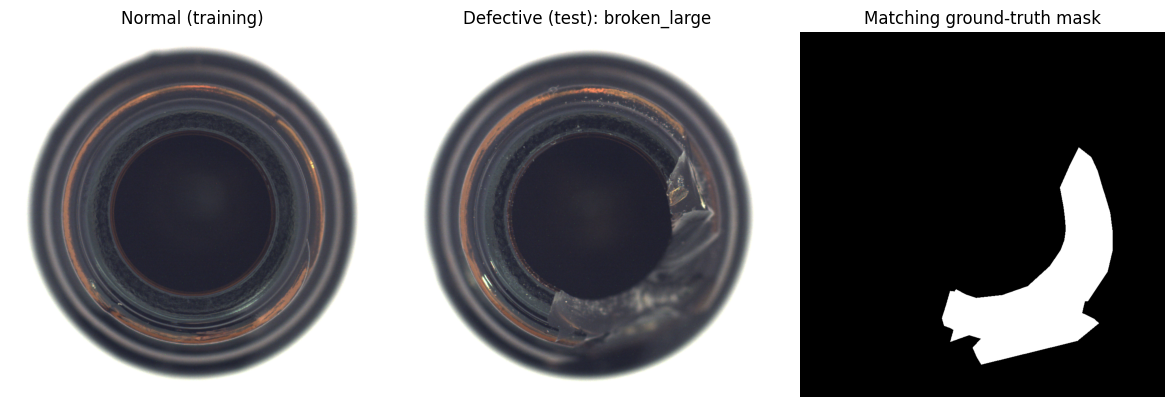

Normal image: 000.png (900, 900)
Defective image: 000.png (900, 900)
Mask: 000_mask.png (900, 900)


In [4]:
from PIL import Image
import matplotlib.pyplot as plt

normal_paths = image_files(BOTTLE_DIR / 'train' / 'good')
assert normal_paths, 'No normal training images were found.'
normal_path = normal_paths[0]

defect_types = [p.name for p in (BOTTLE_DIR / 'test').iterdir()
                if p.is_dir() and p.name != 'good' and image_files(p)]
assert defect_types, 'No defective test images were found.'
defect_type = sorted(defect_types)[0]
defect_path = image_files(BOTTLE_DIR / 'test' / defect_type)[0]
mask_path = BOTTLE_DIR / 'ground_truth' / defect_type / f'{defect_path.stem}_mask.png'
if not mask_path.is_file():
    raise FileNotFoundError(f'Expected matching defect mask was not found: {mask_path}')

normal = Image.open(normal_path).convert('RGB')
defective = Image.open(defect_path).convert('RGB')
mask = Image.open(mask_path).convert('L')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(normal);    axes[0].set_title('Normal (training)')
axes[1].imshow(defective); axes[1].set_title(f'Defective (test): {defect_type}')
axes[2].imshow(mask, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Matching ground-truth mask')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print('Normal image:', normal_path.name, normal.size)
print('Defective image:', defect_path.name, defective.size)
print('Mask:', mask_path.name, mask.size)

## 5. Check the planned neural-network input size

Our later DINOv3 and Student CNN stages will use **224 × 224 RGB** images. Here we check only shape and pixel range.

In [5]:
import numpy as np
import torch

resized = normal.resize((224, 224), Image.Resampling.BILINEAR)
array = np.asarray(resized, dtype=np.float32) / 255.0
tensor = torch.from_numpy(array).permute(2, 0, 1).contiguous()

print('Prepared input tensor shape:', tuple(tensor.shape))
print('Pixel range:', float(tensor.min()), 'to', float(tensor.max()))
assert tuple(tensor.shape) == (3, 224, 224)
print('Stage 1 tensor check passed.')

Prepared input tensor shape: (3, 224, 224)
Pixel range: 0.12156862765550613 to 1.0
Stage 1 tensor check passed.


---
## Stage 2 — Frozen DINOv3 teacher features

The teacher implementation lives in **`final/teacher.py`** in our GitHub repository. This is still our **single master notebook**: it imports the teacher rather than repeating the model code. We will append the student and segmentation stages here later.

**Before running this stage:**
1. Commit **both** `final/AnomaForge.ipynb` and `final/teacher.py` to the public team repository.
2. Get access to [Meta's DINOv3 ViT-S/16 checkpoint](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m).
3. Change `REPO_URL` in the next setup cell to your team's **actual public repository URL**.

We reuse the `normal` PIL image loaded in Stage 1, but run DINOv3's own preprocessing inside `teacher.py`. No model is trained in this stage.

In [ ]:
# Stage 2A: Install libraries in the Colab runtime (run once per fresh runtime).
%pip -q install -U "transformers>=4.56.0" huggingface_hub accelerate

In [ ]:
# Stage 2B: Fetch teacher.py from the team's PUBLIC GitHub repository.
# Replace REPO_URL with the actual GitHub URL BEFORE running this cell.
# On a fresh Colab session, /content is temporary, so we clone again.
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/OWNER/REPOSITORY.git"  # <-- CHANGE THIS
REPO_DIR = Path("/content/anomaforge_repo")

if "OWNER/REPOSITORY" in REPO_URL:
    raise ValueError("Edit REPO_URL to your team's public GitHub repository first.")

if (REPO_DIR / ".git").is_dir():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

MODULE_DIR = REPO_DIR / "final"
if not (MODULE_DIR / "teacher.py").is_file():
    raise FileNotFoundError(f"Missing {MODULE_DIR / 'teacher.py'}. Commit it to GitHub under final/ first.")

if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

from teacher import DINOv3Teacher
print("Loaded helper from:", MODULE_DIR / "teacher.py")

In [ ]:
# Stage 2C: Load frozen teacher and extract the normal bottle's spatial features.
# You must have accepted the DINOv3 license on Hugging Face.
from huggingface_hub import login
import torch

login()  # Follow the prompt; do NOT paste access tokens into the notebook.
assert "normal" in globals(), "Run Stage 1 first to load the normal PIL image."

teacher = DINOv3Teacher()
teacher_pixels, teacher_features = teacher.extract(normal)

print("Device:", teacher.device)
print("DINOv3 preprocessed pixels:", tuple(teacher_pixels.shape))
print("Teacher spatial features:", tuple(teacher_features.shape))
print("Teacher frozen:", all(not p.requires_grad for p in teacher.model.parameters()))

assert tuple(teacher_pixels.shape) == (1, 3, 224, 224)
assert tuple(teacher_features.shape) == (1, 384, 14, 14)
print("Stage 2 passed: DINOv3 spatial features ready for StudentCNN later.")

**Stage 2 success condition:** the last cell prints `Teacher spatial features: (1, 384, 14, 14)` and confirms the model is frozen.

**Next stage (not implemented yet):** Build our custom Student CNN and train it on normal images to match these teacher features. During student training, use the same preprocessing that produced `teacher_pixels` so teacher and student receive consistent inputs.